Original shape: (953, 24)

Original dtypes (first few columns):
track_name        object
artist(s)_name    object
artist_count       int64
released_year      int64
released_month     int64
dtype: object

Example rows:
                            track_name    artist(s)_name  artist_count  \
0  Seven (feat. Latto) (Explicit Ver.)  Latto, Jung Kook             2   
1                                 LALA       Myke Towers             1   
2                              vampire    Olivia Rodrigo             1   

   released_year  released_month  released_day  in_spotify_playlists  \
0           2023               7            14                   553   
1           2023               3            23                  1474   
2           2023               6            30                  1397   

   in_spotify_charts    streams  in_apple_playlists  ...  bpm key   mode  \
0                147  141381703                  43  ...  125   B  Major   
1                 48  133716286             

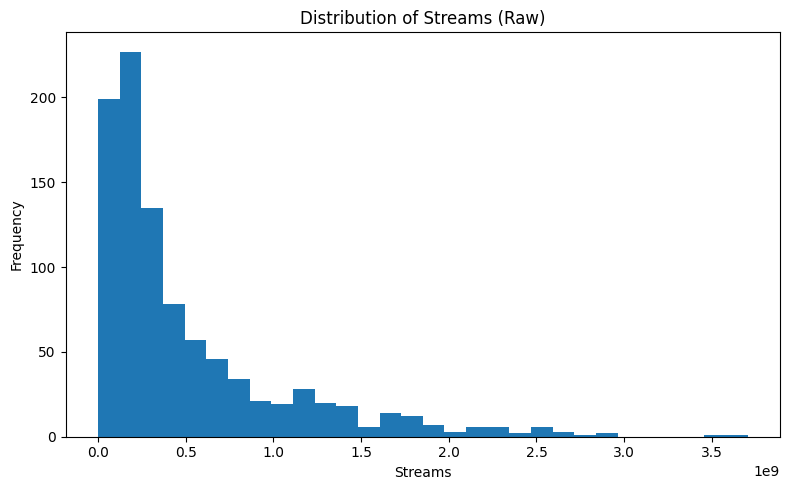


Descriptive statistics for 'log_streams':
count    952.000000
mean      19.506648
std        1.146289
min        7.924072
25%       18.768772
50%       19.487220
75%       20.328546
90%       20.987279
95%       21.286972
99%       21.664237
max       22.032651
Name: log_streams, dtype: float64


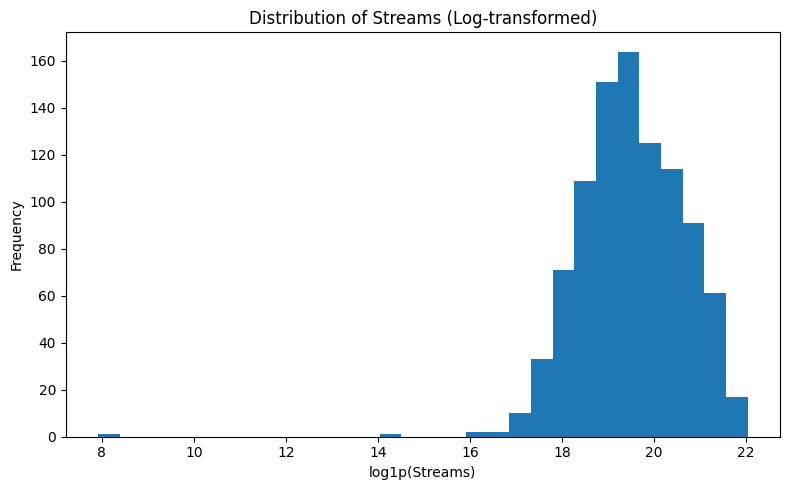


Number of extreme outliers detected (|z| > 3): 2

Extreme outliers:
            track_name                                     artist(s)_name  \
123        Que Vuelvas                         Carin Leon, Grupo Frontera   
393  Jhoome Jo Pathaan  Arijit Singh, Vishal Dadlani, Sukriti Kakar, V...   

       streams  log_streams  
123     2762.0     7.924072  
393  1365184.0    14.126801  

Rows before outlier removal: 952
Rows after outlier removal:  950
Rows removed as outliers:    2

Descriptive statistics for 'log_streams' after outlier removal:
count    950.000000
mean      19.524504
std        1.069843
min       16.266463
25%       18.773839
50%       19.489765
75%       20.328748
90%       20.987472
95%       21.287219
99%       21.664283
max       22.032651
Name: log_streams, dtype: float64


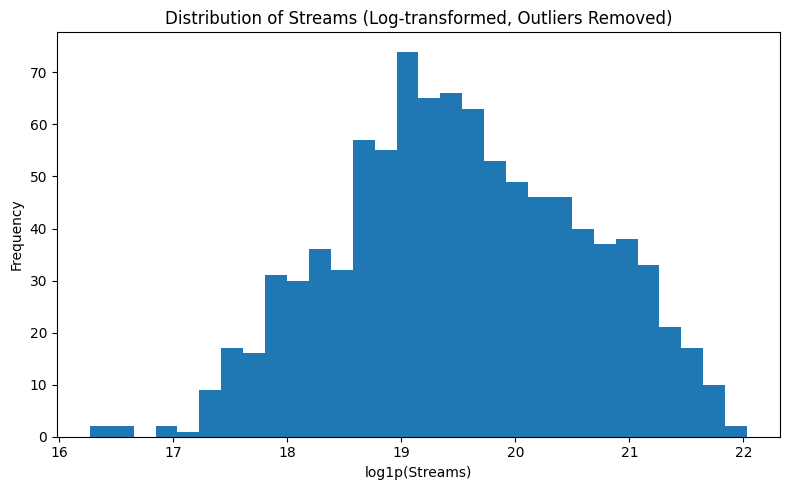


Final cleaned dataset shape: (950, 25)
Columns in cleaned dataset:
['track_name', 'artist(s)_name', 'artist_count', 'released_year', 'released_month', 'released_day', 'in_spotify_playlists', 'in_spotify_charts', 'streams', 'in_apple_playlists', 'in_apple_charts', 'in_deezer_playlists', 'in_deezer_charts', 'in_shazam_charts', 'bpm', 'key', 'mode', 'danceability_%', 'valence_%', 'energy_%', 'acousticness_%', 'instrumentalness_%', 'liveness_%', 'speechiness_%', 'log_streams']

Cleaned dataset saved as: spotify_initial_prepared.csv


In [2]:
# ============================================
# PART 3 – INITIAL DATA PREPARATION (FINAL)
# Clean once and save prepared CSV for modelling
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# --------------------------------------------
# 3.0 Load original raw dataset
# --------------------------------------------
file_path = "spotify_2023.csv"  # adjust path if needed
df = pd.read_csv(file_path, encoding="latin1")

print("Original shape:", df.shape)
print("\nOriginal dtypes (first few columns):")
print(df.dtypes.head())
print("\nExample rows:")
print(df.head(3))

# --------------------------------------------
# 3.1 Convert “streams” and other numeric-like columns to numeric
#      (remove commas like '1,066' and convert to float)
# --------------------------------------------

numeric_cols = [
    "streams",
    "artist_count",
    "released_year",
    "released_month",
    "released_day",
    "in_spotify_playlists",
    "in_spotify_charts",
    "in_apple_playlists",
    "in_apple_charts",
    "in_deezer_playlists",
    "in_deezer_charts",
    "in_shazam_charts",
    "bpm",
    "danceability_%",
    "valence_%",
    "energy_%",
    "acousticness_%",
    "instrumentalness_%",
    "liveness_%",
    "speechiness_%",
]

print("\nConverting numeric-like columns (removing commas and casting to float)...")

for col in numeric_cols:
    if col in df.columns:
        # Convert to string, remove commas (thousands separator), then to numeric
        df[col] = (
            df[col]
            .astype(str)
            .str.replace(",", "", regex=False)
        )
        df[col] = pd.to_numeric(df[col], errors="coerce")
    else:
        print(f"WARNING: Column '{col}' not found in dataset.")

# Drop rows where streams could not be converted
rows_before = df.shape[0]
df = df.dropna(subset=["streams"])
rows_after = df.shape[0]

print(f"\nRows before dropping invalid 'streams': {rows_before}")
print(f"Rows after dropping invalid 'streams':  {rows_after}")
print(f"Rows dropped due to invalid 'streams':  {rows_before - rows_after}")

print("\nDtypes after numeric conversion (selected columns):")
print(df[numeric_cols].dtypes)

# --------------------------------------------
# 3.2 Examine distribution of raw streams and identify skewness
# --------------------------------------------
streams_stats_before = df["streams"].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
)
print("\nDescriptive statistics for raw 'streams':")
print(streams_stats_before)

plt.figure(figsize=(8, 5))
plt.hist(df["streams"], bins=30)
plt.xlabel("Streams")
plt.ylabel("Frequency")
plt.title("Distribution of Streams (Raw)")
plt.tight_layout()
plt.show()

# --------------------------------------------
# 3.3 Apply log transformation to “streams”
# --------------------------------------------
df["log_streams"] = np.log1p(df["streams"])  # log(1 + streams)

streams_stats_log = df["log_streams"].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
)
print("\nDescriptive statistics for 'log_streams':")
print(streams_stats_log)

plt.figure(figsize=(8, 5))
plt.hist(df["log_streams"], bins=30)
plt.xlabel("log1p(Streams)")
plt.ylabel("Frequency")
plt.title("Distribution of Streams (Log-transformed)")
plt.tight_layout()
plt.show()

# --------------------------------------------
# 3.4 Detect and remove extreme outliers (|z| > 3) on log_streams
# --------------------------------------------
z_scores = np.abs(stats.zscore(df["log_streams"], nan_policy="omit"))
outlier_mask = z_scores > 3
outliers_count = outlier_mask.sum()

print(f"\nNumber of extreme outliers detected (|z| > 3): {outliers_count}")

# View the extreme outliers (useful for the report)
extreme_outliers = df.loc[outlier_mask, ["track_name", "artist(s)_name", "streams", "log_streams"]]
print("\nExtreme outliers:")
print(extreme_outliers)

rows_before_outlier = df.shape[0]
df_clean = df.loc[~outlier_mask].copy()
rows_after_outlier = df_clean.shape[0]

print(f"\nRows before outlier removal: {rows_before_outlier}")
print(f"Rows after outlier removal:  {rows_after_outlier}")
print(f"Rows removed as outliers:    {rows_before_outlier - rows_after_outlier}")

streams_stats_clean = df_clean["log_streams"].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
)
print("\nDescriptive statistics for 'log_streams' after outlier removal:")
print(streams_stats_clean)

plt.figure(figsize=(8, 5))
plt.hist(df_clean["log_streams"], bins=30)
plt.xlabel("log1p(Streams)")
plt.ylabel("Frequency")
plt.title("Distribution of Streams (Log-transformed, Outliers Removed)")
plt.tight_layout()
plt.show()

# --------------------------------------------
# 3.5 Outcome of Initial Data Preparation – Save cleaned dataset
# --------------------------------------------
print("\nFinal cleaned dataset shape:", df_clean.shape)
print("Columns in cleaned dataset:")
print(df_clean.columns.tolist())

clean_file_path = "spotify_initial_prepared.csv"
df_clean.to_csv(clean_file_path, index=False)

print(f"\nCleaned dataset saved as: {clean_file_path}")
